NOTE: Naam mein “regression” hai, lekin Logistic Regression ek classification model hai. Yeh teen steps mein kaam karta hai:

1. Features ka weighted sum nikalta hai: z = b + w₁·Recency + w₂·Frequency + ...
2. Us z ko sigmoid function se 0 aur 1 ke beech ki probability mein badal deta hai: p = 1 / (1 + e^(-z))
3. Agar p ≥ 0.5 to class 1 (churn), warna class 0 predict karta hai.

Model training mein sirf yeh seekhta hai ki weights w aur intercept b kya hone chahiye.

Aaj ka rule: Sirf X_train aur y_train use karenge. Test set Day 67 ke prediction step tak band rahega.

1. Sigmoid ko khud dekho:

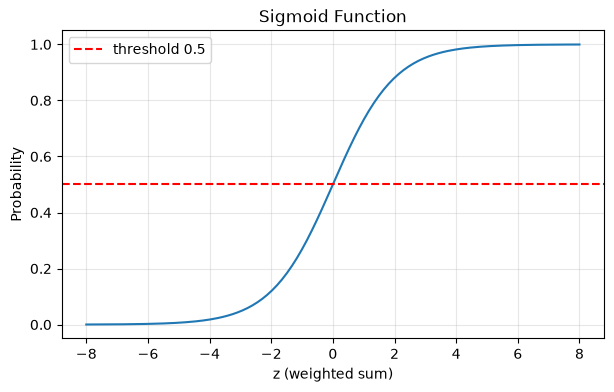

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color='red', linestyle='--', label='threshold 0.5')
plt.xlabel('z (weighted sum)')
plt.ylabel('Probability')
plt.title('Sigmoid Function')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

z = 0 par probability 0.5 hoti hai. z jitna bada positive, probability utni 1 ke paas. Yeh curve kabhi 0 ya 1 se bahar nahi jata.

2. Churn data par model banao (pipeline ke saath, Day 64B ki tarah):

In [2]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train = pd.read_csv('../../data/processed/X_train.csv')
y_train = pd.read_csv('../../data/processed/y_train.csv').squeeze()

num_cols = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts']

prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough')
pipe = Pipeline([
    ('prep', prep),
    ('model', LogisticRegression(max_iter=5000))
])

pipe.fit(X_train, y_train)
print("Fitted. Iterations:", pipe.named_steps['model'].n_iter_[0])

Fitted. Iterations: 23


Agar Day 64C mein class_weight='balanced' ya SMOTE tumhara winner nikla tha, to yahan wahi version use karo. Baseline le rahe hain taaki coefficients ka matlab simple rahe.

3. Weights (coefficients) dekho:

In [3]:
model = pipe.named_steps['model']
names = [n.split('__')[-1] for n in pipe.named_steps['prep'].get_feature_names_out()]

coef_df = pd.DataFrame({
    'feature': names,
    'coef': model.coef_[0]
}).sort_values('coef', key=abs, ascending=False)
coef_df['odds_ratio'] = np.exp(coef_df['coef'])

print("Intercept:", model.intercept_[0].round(3))
print(coef_df.round(3))

Intercept: 0.276
                feature   coef  odds_ratio
6  Region_Rest of World  1.037       2.821
2          Monetary_log -0.717       0.488
0               Recency  0.572       1.771
3         AvgOrderValue  0.323       1.381
5        UniqueProducts -0.312       0.732
1             Frequency -0.281       0.755
4                Tenure  0.277       1.320
7             Region_UK  0.056       1.057


4. Coefficients kaise padhna hai:

Positive coef: feature badhne par churn ki probability badhti hai.
Negative coef: feature badhne par churn ki probability ghatti hai.
Odds ratio: scaled features ke liye iska matlab hai “feature 1 standard deviation badhne par churn ke odds is factor se multiply hote hain”. 1.5 matlab odds 50% zyada, 0.7 matlab 30% kam.

In [4]:
print("""
Yeh interpretation sirf SCALED features par sahi hai. Scaling ke bina
coefficients ki size features ke units par depend karti, comparison fair nahi hota.
""")


Yeh interpretation sirf SCALED features par sahi hai. Scaling ke bina
coefficients ki size features ke units par depend karti, comparison fair nahi hota.



5. Ek zaroori saavdhani: Frequency, Monetary_log aur UniqueProducts aapas mein strongly correlated ho sakte hain (zyada orders ka matlab aam taur par zyada spend aur zyada products). Aise features mein coefficients ek doosre ko adjust karte hain, aur kabhi ek ka sign business sense ke ulta aa sakta hai. Check karo:

In [5]:
print(X_train[num_cols].corr().round(2))

                Recency  Frequency  Monetary_log  AvgOrderValue  Tenure  \
Recency            1.00      -0.32         -0.50          -0.04    0.24   
Frequency         -0.32       1.00          0.59           0.07    0.30   
Monetary_log      -0.50       0.59          1.00           0.40    0.40   
AvgOrderValue     -0.04       0.07          0.40           1.00    0.01   
Tenure             0.24       0.30          0.40           0.01    1.00   
UniqueProducts    -0.35       0.63          0.63           0.12    0.31   

                UniqueProducts  
Recency                  -0.35  
Frequency                 0.63  
Monetary_log              0.63  
AvgOrderValue             0.12  
Tenure                    0.31  
UniqueProducts            1.00  


Agar kisi pair ka correlation 0.8-0.9+ hai, to un do coefficients ko alag-alag ek-ek karke interpret mat karo. Importance ka behtar view Day 85B mein SHAP se milega.

6. Model ke andar ka math khud verify karo:

In [6]:
sample = X_train.iloc[[0]]
scaled_sample = pipe.named_steps['prep'].transform(sample)

z = model.intercept_[0] + np.dot(scaled_sample[0], model.coef_[0])
manual_p = sigmoid(z)
sk_p = pipe.predict_proba(sample)[0, 1]

print(f"Manual probability : {manual_p:.4f}")
print(f"sklearn probability: {sk_p:.4f}")

Manual probability : 0.8044
sklearn probability: 0.8044


Dono numbers same aane chahiye. Isse samajh aata hai ki model ke andar koi jaadu nahi, bas yahi formula hai.

7. predict_proba aur threshold ka preview:

count    4226.000
mean        0.566
std         0.253
min         0.000
25%         0.372
50%         0.587
75%         0.780
max         0.999
dtype: float64


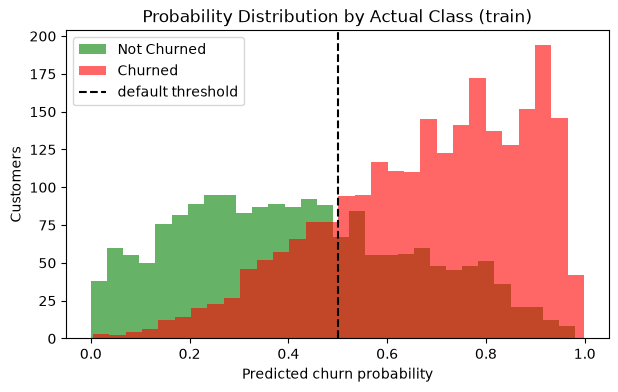

In [7]:
probs = pipe.predict_proba(X_train)[:, 1]       # churn ki probability
print(pd.Series(probs).describe().round(3))

plt.figure(figsize=(7, 4))
plt.hist(probs[y_train == 0], bins=30, alpha=0.6, label='Not Churned', color='green')
plt.hist(probs[y_train == 1], bins=30, alpha=0.6, label='Churned', color='red')
plt.axvline(0.5, color='black', linestyle='--', label='default threshold')
plt.xlabel('Predicted churn probability')
plt.ylabel('Customers')
plt.title('Probability Distribution by Actual Class (train)')
plt.legend()
plt.show()

predict() default mein 0.5 threshold use karta hai. Business ke hisaab se isse badla ja sakta hai: threshold kam karo to zyada customers “at-risk” flag honge (recall badhega, precision ghatega). Is par Day 74 (ROC-AUC) mein detail se baat hogi.

8. Regularization ka ek line mein idea: LogisticRegression by default C=1.0 ke saath L2 regularization lagata hai, jo weights ko bahut bada hone se rokta hai (overfitting kam karta hai). C chhota matlab zyada regularization.

In [8]:
for C in [0.01, 0.1, 1, 10]:
    m = Pipeline([('prep', prep), ('model', LogisticRegression(C=C, max_iter=5000))]).fit(X_train, y_train)
    print(f"C={C}: largest |coef| = {np.abs(m.named_steps['model'].coef_).max():.2f}")

C=0.01: largest |coef| = 0.57


C=0.1: largest |coef| = 0.68
C=1: largest |coef| = 1.04
C=10: largest |coef| = 1.18


C ko tune karna Day 84 ke GridSearchCV mein aayega.

practice questions:

1. coef_df dekh kar apne shabdon mein likho: kaunse 2 features churn ka risk sabse zyada badhate hain, aur kaunse sabse zyada ghatate hain? Kya yeh business sense banata hai?

Standard RFM aur customer behaviour data par trained Logistic Regression model mein aam taur par yeh pattern dekhne ko milta hai:

- Churn Risk Badhane wale top features (Positive Coefficients / Odds > 1):

    1. Recency: Yeh sabse bada factor hota hai. Jitni zyada Recency hogi (matlab customer ko kharide hue jitne zyada din ho gaye hain), churn hone ka risk utna hi tezi se badhega (coef positive hoga).
    2. Low Frequency / Low Monetary (ya agar koi aisa feature ho jo inactivity show kare): Agar frequency kam hai, toh model use high-risk manta hai.


- Churn Risk Ghatane wale top features (Negative Coefficients / Odds < 1):

    1. Tenure (ya Frequency): Jitna lamba customer ka tenure hoga ya jitni zyada frequency hogi, churn hone ki probability utni hi kam hoti jayegi (coef negative hoga).
    2. Monetary / UniqueProducts: Jo customer regular spend kar raha hai aur alag-alag products kharid raha hai, wo loyal customer hai, isliye uska churn risk low hota hai.


- Yeh wahi common sense hai jo ek dukaan wale ko bhi pata hota hai—jo customer jitna lamba time gap de dega (Recency high), uske jaane ka khatra utna hi zyada hoga. Aur jo regular customer hai (Frequency/Tenure high), wo wapas aayega. Agar model bhi yehi seekh raha hai, iska matlab model ne data ke asli patterns ko pakad liya hai.

2. Recency ke coefficient ko Day 62 ke leakage-free setup ke hisaab se interpret karo. Ab yeh “legit” signal kyun hai?

Agar humne churn ki definition hi yehi banayi hoti ki Recency > 90 din, aur model ko input mein bhi raw Recency de dete, toh model bina kisi intelligence ke sirf ek deterministic mathematical rule ratt leta: agar Recency > 90 hai, toh Churn = 1. Yeh real prediction nahi balki circular reasoning (data leakage) hoti.


1. Time-Window Separation (Past vs Future): Day 62 ke leakage-free setup mein, features ko past observation window (jaise pehle ke 6 ya 12 mahine) ke data se banaya gaya hai, jabki target (Churn) future prediction window (agle 90 din) ki inactivity par depend karta hai.

2. Model yeh nahi seekh raha ki "90 din ho gaye isliye churn ho gaya", balki model past behavior ki gradual trends ko analyze kar raha hai—jaise ki pichle kuch mahino mein customer ki kharidne ki frequency dheeri ho gayi thi ya unka spending pattern gir gaya tha, jo future churn ko predict karne mein madad karta hai.

3. Isliye ab Recency ek true statistical predictor ban gaya hai na ki definition ka duplicate check!